# CoNLL-2003 — Task 2: Data EDA

Exploratory analysis and data-preparation walkthrough for the NER task. All processing lives in `src/conll_data.py` (run `python src/conll_data.py` to create `data/conll2003/`); this notebook reads those files and writes tables/figures to `results/task2_data/`.

- **Dataset:** [extraordinarylab/conll2003](https://huggingface.co/datasets/extraordinarylab/conll2003) (Parquet copy of the original; dataset card: [eriktks/conll2003](https://huggingface.co/datasets/eriktks/conll2003)) — Tjong Kim Sang & De Meulder (2003), *Introduction to the CoNLL-2003 Shared Task: Language-Independent Named Entity Recognition*, CoNLL.
- **Source:** Reuters news stories (1996–1997), pre-tokenized into words.
- **Entity types (4):** `PER` (person), `ORG` (organization), `LOC` (location), `MISC` (miscellaneous: nationalities, events, products...).
- **Splits:** the official train / validation / test splits are used unchanged.

Output files in `data/conll2003/`:

| File | Content |
|---|---|
| `{train,val,test}.jsonl` | one sentence per line: `tokens`, `ner_tags` (BIO), `ner_tags_bioes` |
| `vocab.json` | `word2idx`, `char2idx`, `tag2idx`, `tag2idx_bioes` (built on train only) |
| `data_summary.json` | sizes, entity counts, OOV rates |

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tìm thư mục gốc repo để chạy được dù kernel mở ở root hay ở notebooks/Task X
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "Task 2").is_dir())
sys.path.insert(0, str(ROOT / "data" / "Task 2"))
import conll_data as cd

TYPE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
SPLIT_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
RESULTS_DIR = ROOT / "data" / "results" / "task2_data"
(RESULTS_DIR / "plots").mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / "tables").mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Chưa có data đã xử lý thì chạy pipeline trước
if not (cd.OUTPUT_DIR / "vocab.json").exists():
    cd.main()
frames, vocabs = cd.load_processed()
summary = json.loads((cd.OUTPUT_DIR / "data_summary.json").read_text())
train_df, val_df, test_df = frames["train"], frames["val"], frames["test"]
train_df.head()

,tokens,ner_tags,ner_tags_bioes
0,"[EU, rejects, German, call, to, boycott, Briti...","[B-ORG, O, B-MISC, O, O, O, B-MISC, O, O]","[S-ORG, O, S-MISC, O, O, O, S-MISC, O, O]"
1,"[Peter, Blackburn]","[B-PER, I-PER]","[B-PER, E-PER]"
2,"[BRUSSELS, 1996-08-22]","[B-LOC, O]","[S-LOC, O]"
3,"[The, European, Commission, said, on, Thursday...","[O, B-ORG, I-ORG, O, O, O, O, O, O, B-MISC, O,...","[O, B-ORG, E-ORG, O, O, O, O, O, O, S-MISC, O,..."
4,"[Germany, 's, representative, to, the, Europea...","[B-LOC, O, O, O, O, B-ORG, I-ORG, O, O, O, B-P...","[S-LOC, O, O, O, O, B-ORG, E-ORG, O, O, O, B-P..."


In [2]:
# Kiểm tra: số token = số nhãn, chuỗi BIO hợp lệ, câu trùng lặp
train_sents = set(map(tuple, train_df["tokens"]))
checks = pd.DataFrame({
    split: {
        "token/tag length mismatch": int((f["tokens"].map(len) != f["ner_tags"].map(len)).sum()),
        "invalid BIO transitions": summary["splits"][split]["invalid_bio_tags"],
        "-DOCSTART- lines": int(f["tokens"].map(lambda t: t[0] == "-DOCSTART-").sum()),
        "duplicate sentences": int(f["tokens"].map(tuple).duplicated().sum()),
        "sentences also in train": None if split == "train" else int(f["tokens"].map(tuple).isin(train_sents).sum()),
    }
    for split, f in frames.items()
}).astype("Int64")
checks

,train,val,test
token/tag length mismatch,0,0,0
invalid BIO transitions,0,0,0
-DOCSTART- lines,0,0,0
duplicate sentences,1350,180,269
sentences also in train,<NA>,193,126


In [3]:
dup_examples = train_df.loc[train_df["tokens"].map(tuple).duplicated(), "tokens"].map(" ".join)
dup_examples.value_counts().head(8)

tokens
Scorers :                                                                         15
EASTERN DIVISION                                                                  15
W L PCT GB                                                                        15
CENTRAL DIVISION                                                                  15
WESTERN DIVISION                                                                  15
for , against , points -RPR- :                                                    15
Women 's singles                                                                  15
Reuters has not verified these stories and does not vouch for their accuracy .    14
Name: count, dtype: int64

Tokens and labels are aligned one-to-one, every `I-X` follows a `B-X` or `I-X` (valid IOB2), and there are no `-DOCSTART-` separators left. The duplicate sentences are short recurring lines such as datelines (`LONDON 1996-08-22`), sports scores and table headers. They are **kept** because CoNLL-2003 is a standard benchmark and removing them would make the scores incomparable with published results.

## 1. Dataset size and entity distribution

In [4]:
size_rows = {}
for split, f in frames.items():
    s = summary["splits"][split]
    size_rows[split] = {
        "sentences": s["sentences"],
        "tokens": s["tokens"],
        "entities": sum(s["entities"].values()),
        "avg tokens / sentence": round(s["tokens"] / s["sentences"], 2),
        "max tokens / sentence": s["max_sentence_len"],
    }
size_df = pd.DataFrame.from_dict(size_rows, orient="index")
size_df.to_csv(RESULTS_DIR / "tables" / "dataset_size.csv")
size_df

,sentences,tokens,entities,avg tokens / sentence,max tokens / sentence
train,14041,203618,23499,14.50,113
val,3250,51360,5942,15.80,109
test,3453,46427,5648,13.45,124


In [5]:
entity_counts = pd.DataFrame({split: summary["splits"][split]["entities"] for split in cd.SPLITS}).loc[cd.ENTITY_TYPES]
entity_pct = (entity_counts / entity_counts.sum() * 100).round(2)
entity_counts.loc["Total"] = entity_counts.sum()
entity_counts.to_csv(RESULTS_DIR / "tables" / "entity_counts.csv")
display(entity_counts)
display(entity_pct.add_suffix(" (%)"))

,train,val,test
PER,6600,1842,1617
ORG,6321,1341,1661
LOC,7140,1837,1668
MISC,3438,922,702
Total,23499,5942,5648


,train (%),val (%),test (%)
PER,28.09,31.00,28.63
ORG,26.90,22.57,29.41
LOC,30.38,30.92,29.53
MISC,14.63,15.52,12.43


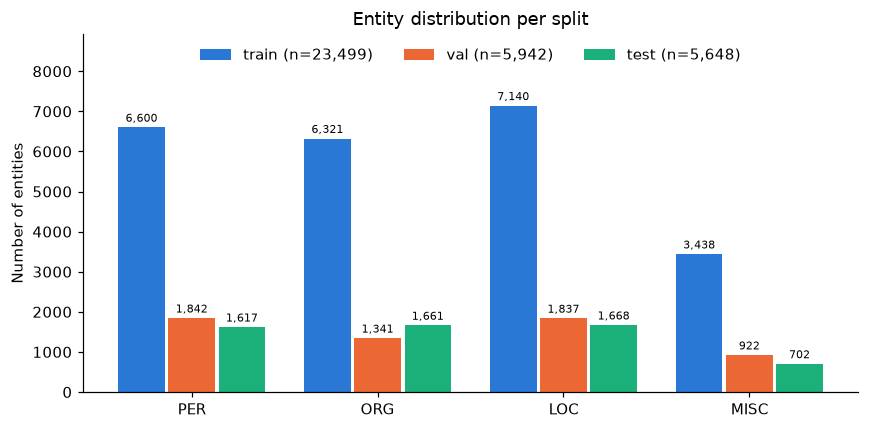

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(cd.ENTITY_TYPES))
width = 0.27
for i, (split, color) in enumerate(zip(cd.SPLITS, SPLIT_COLORS)):
    counts = entity_counts.loc[cd.ENTITY_TYPES, split]
    bars = ax.bar(x + (i - 1) * width, counts, width - 0.02, color=color, label=f"{split} (n={counts.sum():,})")
    ax.bar_label(bars, labels=[f"{v:,}" for v in counts], fontsize=7, padding=2)
ax.set_xticks(x, cd.ENTITY_TYPES)
ax.set_ylim(0, entity_counts.loc[cd.ENTITY_TYPES].values.max() * 1.25)
ax.set_ylabel("Number of entities")
ax.set_title("Entity distribution per split")
ax.legend(frameon=False, ncol=3, loc="upper center")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "plots" / "entity_distribution.png", bbox_inches="tight")
plt.show()

In [7]:
tag_counts = pd.DataFrame({
    split: pd.Series(Counter(t for tags in f["ner_tags"] for t in tags)).reindex(cd.BIO_TAGS)
    for split, f in frames.items()
})
tag_pct = tag_counts / tag_counts.sum() * 100
tag_table = tag_counts.apply(lambda col: [f"{c:,} ({p:.2f}%)" for c, p in zip(col, tag_pct[col.name])])
tag_counts.to_csv(RESULTS_DIR / "tables" / "tag_counts.csv")
tag_table

,train,val,test
O,"169,575 (83.28%)","42,757 (83.25%)","38,315 (82.53%)"
B-PER,"6,600 (3.24%)","1,842 (3.59%)","1,617 (3.48%)"
I-PER,"4,528 (2.22%)","1,307 (2.54%)","1,156 (2.49%)"
B-ORG,"6,321 (3.10%)","1,341 (2.61%)","1,661 (3.58%)"
I-ORG,"3,704 (1.82%)",751 (1.46%),835 (1.80%)
B-LOC,"7,140 (3.51%)","1,837 (3.58%)","1,668 (3.59%)"
I-LOC,"1,157 (0.57%)",257 (0.50%),257 (0.55%)
B-MISC,"3,438 (1.69%)",922 (1.80%),702 (1.51%)
I-MISC,"1,155 (0.57%)",346 (0.67%),216 (0.47%)


`PER`, `ORG` and `LOC` have similar frequencies while `MISC` is the rarest type in every split. At the token level about 83% of the labels are `O`: a model predicting only `O` would reach ~83% token accuracy while finding no entity at all, which is why the evaluation uses **entity-level** precision/recall/F1.

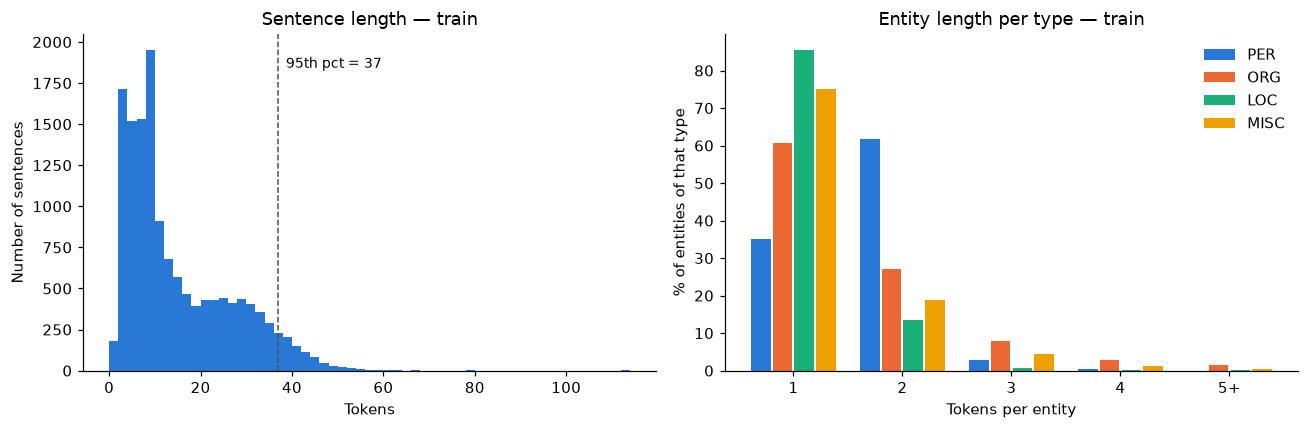

,mean,max,single_token_pct
type,,,
PER,1.69,6,35.09
ORG,1.59,10,60.69
LOC,1.16,10,85.42
MISC,1.34,7,75.04


In [8]:
sent_len = train_df["tokens"].map(len)
entity_rows = []
for split, f in frames.items():
    for tags in f["ner_tags"]:
        for ent_type, start, end in cd.get_entities(tags):
            entity_rows.append({"split": split, "type": ent_type, "length": end - start})
entity_len = pd.DataFrame(entity_rows)
entity_len_stats = entity_len[entity_len["split"] == "train"].groupby("type")["length"].agg(
    mean="mean", max="max", single_token_pct=lambda s: (s == 1).mean() * 100,
).reindex(cd.ENTITY_TYPES).round(2)
entity_len_stats.to_csv(RESULTS_DIR / "tables" / "entity_length_stats.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
p95 = np.percentile(sent_len, 95)
axes[0].hist(sent_len, bins=range(0, sent_len.max() + 2, 2), color=SPLIT_COLORS[0])
axes[0].axvline(p95, color="#52514e", linestyle="--", linewidth=1)
axes[0].annotate(f"95th pct = {p95:.0f}", (p95, axes[0].get_ylim()[1] * 0.9), xytext=(5, 0), textcoords="offset points", fontsize=9)
axes[0].set_title("Sentence length — train")
axes[0].set_xlabel("Tokens")
axes[0].set_ylabel("Number of sentences")

train_len = entity_len[entity_len["split"] == "train"]
max_k = 5
for i, (ent_type, color) in enumerate(zip(cd.ENTITY_TYPES, TYPE_COLORS)):
    share = train_len.loc[train_len["type"] == ent_type, "length"].clip(upper=max_k).value_counts(normalize=True)
    share = share.reindex(range(1, max_k + 1), fill_value=0) * 100
    axes[1].bar(np.arange(1, max_k + 1) + (i - 1.5) * 0.2, share, 0.18, color=color, label=ent_type)
axes[1].set_xticks(range(1, max_k + 1), [str(k) for k in range(1, max_k)] + [f"{max_k}+"])
axes[1].set_title("Entity length per type — train")
axes[1].set_xlabel("Tokens per entity")
axes[1].set_ylabel("% of entities of that type")
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "plots" / "length_distribution.png", bbox_inches="tight")
plt.show()
entity_len_stats

Sentences are short (many 1–2 token lines are datelines or headers) with a long tail. Most entities are one or two tokens. `PER` is the only type that is usually multi-token (first + last name; only 35% are single tokens), while 85% of `LOC` and 75% of `MISC` entities are single tokens. Multi-token entities are where boundary errors can happen.

## 2. Annotation format: BIO (IOB2)

Each token has one label. `B-X` marks the first token of an entity of type `X`, `I-X` a following token inside the same entity, and `O` a token outside any entity. The pipeline also provides a **BIOES** version (`E-X` = last token of a multi-token entity, `S-X` = single-token entity), which makes entity boundaries explicit and can be tried as an alternative tagging scheme. BIOES predictions are mapped back to BIO with `cd.bioes_to_bio` before evaluation, so scores stay comparable across schemes.

In [9]:
example = pd.concat([
    pd.DataFrame({"token": r["tokens"], "BIO": r["ner_tags"], "BIOES": r["ner_tags_bioes"]})
    for _, r in train_df.iloc[[0, 1]].iterrows()
], keys=[1, 2], names=["sentence", "position"])
example.to_csv(RESULTS_DIR / "tables" / "bio_example.csv")
example

token     BIO   BIOES
sentence position                           
1        0                EU   B-ORG   S-ORG
         1           rejects       O       O
         2            German  B-MISC  S-MISC
         3              call       O       O
         4                to       O       O
         5           boycott       O       O
         6           British  B-MISC  S-MISC
         7              lamb       O       O
         8                 .       O       O
2        0             Peter   B-PER   B-PER
         1         Blackburn   I-PER   E-PER

## 3. Tokenization, token–label alignment, padding and unknown words

**Tokenization.** CoNLL-2003 is distributed already tokenized into words (one token per line in the original files), so the given tokens are used as is; no further tokenizer is applied.

**Token–label alignment.** Because the models use word-level embeddings, there is exactly one label per token and no re-alignment is needed. (With a subword tokenizer such as BERT's WordPiece, one word can be split into several pieces; the usual approach labels only the first piece and gives the others the label `-100` so the loss ignores them.)

**Vocabularies** (`vocab.json`, built on the training split only, so validation/test words never leak into the vocabulary):

- `word2idx`: `<PAD>` = 0, `<UNK>` = 1, then every normalized training word. Normalization = lowercase + replace digits by `0` (`cd.normalize_word`), which merges case variants and numbers (`1996-08-22` → `0000-00-00`) and matches the lowercased GloVe vocabulary. Capitalization lost by lowercasing can be recovered with the character-level embeddings.
- `char2idx`: `<PAD>` = 0, `<UNK>` = 1, then every character seen in training (case-sensitive).
- `tag2idx` (9 BIO labels) and `tag2idx_bioes` (17 BIOES labels).

**Padding.** Sentences are padded per batch to the longest sentence in that batch with `<PAD>` (id 0, the embedding `padding_idx`). Padded positions get the label `-100`, so `CrossEntropyLoss(ignore_index=-100)` skips them, and they are removed before entity-level evaluation.

In [10]:
# Minh hoạ padding một batch 3 câu: id từ và nhãn, vị trí đệm có nhãn -100
word2idx, tag2idx = vocabs["word2idx"], vocabs["tag2idx"]
batch = train_df.iloc[[0, 1, 2]]
max_len = batch["tokens"].map(len).max()

rows = []
for i, (tokens, tags) in enumerate(zip(batch["tokens"], batch["ner_tags"])):
    pad = max_len - len(tokens)
    rows.append({
        "sentence": i + 1,
        "tokens": tokens + [cd.PAD] * pad,
        "word ids": [word2idx.get(cd.normalize_word(w), word2idx[cd.UNK]) for w in tokens] + [word2idx[cd.PAD]] * pad,
        "label ids": [tag2idx[t] for t in tags] + [cd.PAD_LABEL_ID] * pad,
    })
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows).set_index("sentence"))

,tokens,word ids,label ids
sentence,,,
1,"[EU, rejects, German, call, to, boycott, British, lamb, .]","[933, 9892, 199, 584, 9, 3759, 208, 5436, 3]","[3, 0, 7, 0, 0, 0, 7, 0, 0]"
2,"[Peter, Blackburn, <PAD>, <PAD>, <PAD>, <PAD>, <PAD>, <PAD>, <PAD>]","[724, 1781, 0, 0, 0, 0, 0, 0, 0]","[1, 2, -100, -100, -100, -100, -100, -100, -100]"
3,"[BRUSSELS, 1996-08-22, <PAD>, <PAD>, <PAD>, <PAD>, <PAD>, <PAD>, <PAD>]","[676, 24, 0, 0, 0, 0, 0, 0, 0]","[5, 0, -100, -100, -100, -100, -100, -100, -100]"


**Unknown words.** Any word whose normalized form is not in `word2idx` is mapped to `<UNK>`. The table below shows how often this happens on validation/test for three levels of normalization, both over all tokens and over tokens inside entities.

In [11]:
oov = pd.DataFrame({split: summary["splits"][split]["oov"] for split in ["val", "test"]})
oov.index = pd.MultiIndex.from_tuples(
    [(k.rsplit("_", 2)[0], k.rsplit("_", 2)[1] + " tokens") for k in oov.index], names=["normalization", "scope"]
)
oov = (oov * 100).round(2).unstack("scope")
oov = oov.reindex(["raw", "lower", "lower_digit0"])
oov.columns = [f"{split} {scope} (%)" for split, scope in oov.columns]
oov.to_csv(RESULTS_DIR / "tables" / "oov_rates.csv")
oov

,val all tokens (%),val entity tokens (%),test all tokens (%),test entity tokens (%)
normalization,,,,
raw,8.36,20.38,12.18,31.27
lower,7.54,18.17,10.88,28.49
lower_digit0,5.96,18.12,8.29,28.49


In [12]:
# Ví dụ câu test có từ lạ -> <UNK>
def show_unk(tokens):
    return " ".join(w if cd.normalize_word(w) in word2idx else f"[{w}→<UNK>]" for w in tokens)

unk_mask = test_df["tokens"].map(lambda t: sum(cd.normalize_word(w) not in word2idx for w in t) >= 2)
for tokens in test_df.loc[unk_mask, "tokens"].head(5):
    print(show_unk(tokens))

[Nadim→<UNK>] [Ladki→<UNK>]
China controlled most of the match and saw several chances missed until the 78th minute when [Uzbek→<UNK>] striker [Igor→<UNK>] [Shkvyrin→<UNK>] took advantage of a [misdirected→<UNK>] defensive header to lob the ball over the advancing Chinese keeper and into an empty net .
[Oleg→<UNK>] [Shatskiku→<UNK>] made sure of the win in injury time , hitting an [unstoppable→<UNK>] left foot shot from just outside the area .
[Takuya→<UNK>] [Takagi→<UNK>] scored the winner in the 88th minute , rising to head a [Hiroshige→<UNK>] [Yanagimoto→<UNK>] cross towards the Syrian goal which goalkeeper [Salem→<UNK>] [Bitar→<UNK>] appeared to have covered but then allowed to slip into the net .
Defender Hassan Abbas rose to [intercept→<UNK>] a long ball into the area in the 84th minute but only managed to [divert→<UNK>] it into the top corner of [Bitar→<UNK>] 's goal .


Normalization removes roughly 30% of the OOV tokens overall (mostly numbers and capitalized variants), but entity tokens remain far more often unknown: about **18% on validation and 28% on test**, versus 6–8% for all tokens. The test set comes from a later period of the Reuters corpus (December 1996, while training is from August 1996), so it contains many names never seen in training. Strategies to handle unknown words, implemented on the model side:

1. **`<UNK>` mapping** with the normalized lookup above (baseline).
2. **Word dropout:** during training, randomly replace ~5% of the word ids with `<UNK>` so the model learns to rely on context when a word is unknown. This matters because `word2idx` contains every training word, so `<UNK>` never occurs in the training data itself; without word dropout its embedding would stay untrained.
3. **Pretrained GloVe embeddings** (lowercased, 400k words) cover many words never seen in CoNLL training data.
4. **Character-level embeddings** (`char2idx`) build a representation for any word from its characters, including capitalization and suffix cues for unseen names.

## 4. Entity surface forms

In [13]:
surface = Counter()
for tokens, tags in zip(train_df["tokens"], train_df["ner_tags"]):
    for ent_type, start, end in cd.get_entities(tags):
        surface[(" ".join(tokens[start:end]), ent_type)] += 1

top_entities = {}
for ent_type in cd.ENTITY_TYPES:
    items = sorted(((s, c) for (s, t), c in surface.items() if t == ent_type), key=lambda x: -x[1])[:10]
    top_entities[ent_type] = [f"{s} ({c})" for s, c in items]
top_entities_df = pd.DataFrame(top_entities)
top_entities_df.index += 1
top_entities_df.to_csv(RESULTS_DIR / "tables" / "top_entities_per_type.csv")
top_entities_df

,PER,ORG,LOC,MISC
1,Clinton (70),Reuters (73),U.S. (303),Russian (92)
2,Dole (36),U.N. (35),Germany (141),German (80)
3,Arafat (35),NEW YORK (30),Britain (133),British (73)
4,Yeltsin (32),CHICAGO (30),Australia (130),French (59)
5,Lebed (30),PUK (25),England (123),Dutch (50)
6,Dutroux (30),OSCE (25),France (122),GMT (49)
7,Wasim Akram (29),EU (23),Spain (110),Israeli (48)
8,Waqar Younis (25),NATO (22),Italy (98),English (38)
9,Mushtaq Ahmed (25),European Union (20),LONDON (93),Iraqi (38)
10,Mother Teresa (20),Honda (20),China (91),European (38)


In [14]:
# Cùng một chuỗi nhưng được gán nhiều loại thực thể khác nhau trong train
by_text = {}
for (text, ent_type), c in surface.items():
    by_text.setdefault(text, {})[ent_type] = c
ambiguous = pd.DataFrame(
    [{"entity": text, **types, "total": sum(types.values())} for text, types in by_text.items() if len(types) > 1]
).fillna(0)
ambiguous = ambiguous[["entity"] + cd.ENTITY_TYPES + ["total"]]
ambiguous[cd.ENTITY_TYPES] = ambiguous[cd.ENTITY_TYPES].astype(int)
ambiguous = ambiguous.sort_values("total", ascending=False).reset_index(drop=True)
ambiguous.to_csv(RESULTS_DIR / "tables" / "ambiguous_entities.csv", index=False)
print(f"{len(ambiguous)} of {len(by_text)} distinct entity strings in train have more than one type")
ambiguous.head(12)

132 of 8082 distinct entity strings in train have more than one type


,entity,PER,ORG,LOC,MISC,total
0,NEW YORK,0,30,65,0,95
1,London,0,5,61,0,66
2,CHICAGO,0,30,29,0,59
3,New York,0,9,35,0,44
4,American,0,1,0,37,38
5,Chicago,0,5,27,0,32
6,Jordan,1,7,24,0,32
7,Washington,3,0,26,0,29
8,Wimbledon,0,8,3,18,29
9,BALTIMORE,0,17,11,0,28


The most frequent entities are politicians (`PER`), countries and cities (`LOC`), nationalities (`MISC`), and news agencies and international organizations (`ORG`). City names in capitals such as `NEW YORK` and `CHICAGO` also rank among the top `ORG` entities: in sports result tables they denote teams. 132 distinct strings receive more than one type depending on context — `CHICAGO` is `LOC` 29 times (datelines) and `ORG` 30 times (the team), `Jordan` is a country or a person, `Wimbledon` is a place, a club or a tournament (`MISC`). These context-dependent cases are a likely source of **wrong-type** errors and should be revisited in the error analysis.